# TASK 6 – MACHINE LEARNING MODEL DEVELOPMENT
## AI-Based Product Review Sentiment Analysis

## 2. AIM
To develop, train, evaluate, and compare multiple machine learning models for product review sentiment classification using the optimized feature set obtained from Task 5.

## 3. OBJECTIVES
1. Load the optimized feature matrix from Task 5.
2. Prepare training and testing datasets.
3. Train multiple classification algorithms.
4. Evaluate each model using standard classification metrics.
5. Generate confusion matrices.
6. Generate ROC curves and AUC scores.
7. Compare model performance.
8. Identify the best-performing model.
9. Save trained models in .pkl format.
10. Generate a complete evaluation and model comparison report.

## 4. IMPORT LIBRARIES

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
from scipy.sparse import hstack, csr_matrix

from sklearn.preprocessing import MaxAbsScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, auc

import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
random_state = 42



## 5. LOAD TASK 5 OUTPUTS

In [17]:
# Load the selected features list
try:
    selected_features_df = pd.read_csv('task5_selected_features.csv')
    selected_feature_names = selected_features_df['Feature'].tolist()
    print(f"Loaded {len(selected_feature_names)} selected features from Task 5.")
except FileNotFoundError:
    print("Warning: task5_selected_features.csv not found.")
    
# Load Data
df = pd.read_csv('clean_product_reviews.csv')
X_train_df = pd.read_csv('X_train.csv')
X_test_df = pd.read_csv('X_test.csv')

print("clean_product_reviews shape:", df.shape)
print("X_train shape:", X_train_df.shape)
print("X_test shape:", X_test_df.shape)

# We need to reconstruct the feature matrix as done in Task 5
# Or if task5_feature_matrix.csv contains the full matrix, load it
# However, task5_feature_matrix.csv usually contains metadata, not the actual sparse matrix.
# Let's rebuild the selected feature matrix quickly.
# Load tfidf
tfidf = joblib.load('task5_tfidf_vectorizer.pkl')

positive_keywords = ['good', 'great', 'best', 'excellent', 'love', 'awesome', 'nice', 'perfect', 'amazing', 'happy']
negative_keywords = ['bad', 'poor', 'terrible', 'worst', 'hate', 'awful', 'waste', 'disappointing', 'boring', 'slow']

def generate_features(data, text_column, raw_text_column=None):
    data = data.copy()
    data[text_column] = data[text_column].fillna('')
    struct_col = raw_text_column if raw_text_column and raw_text_column in data.columns else text_column
    data[struct_col] = data[struct_col].fillna('')

    data['review_length'] = data[struct_col].apply(len)
    data['word_count'] = data[struct_col].apply(lambda x: len(x.split()))
    data['character_count'] = data['review_length']
    data['sentence_count'] = data[struct_col].apply(lambda x: x.count('.') + x.count('!') + x.count('?') + 1)
    data['average_word_length'] = data.apply(lambda row: row['character_count'] / row['word_count'] if row['word_count'] > 0 else 0, axis=1)
    data['exclamation_count'] = data[struct_col].apply(lambda x: x.count('!'))
    data['question_count'] = data[struct_col].apply(lambda x: x.count('?'))
    data['uppercase_count'] = data[struct_col].apply(lambda x: sum(1 for c in x if c.isupper()))
    data['digit_count'] = data[struct_col].apply(lambda x: sum(1 for c in x if c.isdigit()))
    data['positive_word_count'] = data[text_column].apply(lambda x: sum(1 for w in x.lower().split() if w in positive_keywords))
    data['negative_word_count'] = data[text_column].apply(lambda x: sum(1 for w in x.lower().split() if w in negative_keywords))
    data['sentiment_keyword_score'] = data['positive_word_count'] - data['negative_word_count']
    
    min_score = data['sentiment_keyword_score'].min()
    if min_score < 0:
        data['sentiment_keyword_score'] = data['sentiment_keyword_score'] - min_score
    return data

text_col = 'clean_review'
df_unique = df.drop_duplicates(subset=[text_col])
X_train_df = X_train_df.merge(df_unique[[text_col, 'review_text', 'sentiment_numeric']], on=text_col, how='left')
X_test_df = X_test_df.merge(df_unique[[text_col, 'review_text', 'sentiment_numeric']], on=text_col, how='left')

X_train_df = generate_features(X_train_df, text_col, raw_text_column='review_text')
X_test_df = generate_features(X_test_df, text_col, raw_text_column='review_text')

engineered_features = ['review_length', 'word_count', 'character_count', 'sentence_count', 
                       'average_word_length', 'exclamation_count', 'question_count', 
                       'uppercase_count', 'digit_count', 'positive_word_count', 
                       'negative_word_count', 'sentiment_keyword_score']

all_feature_names = engineered_features + list(tfidf.get_feature_names_out())
selected_indices = [all_feature_names.index(f) for f in selected_feature_names if f in all_feature_names]
print(f"Mapped {len(selected_indices)} features.")

X_train_tfidf = tfidf.transform(X_train_df[text_col])
X_test_tfidf = tfidf.transform(X_test_df[text_col])

X_train_eng_sparse = csr_matrix(X_train_df[engineered_features].values)
X_test_eng_sparse = csr_matrix(X_test_df[engineered_features].values)

X_train_full = hstack([X_train_eng_sparse, X_train_tfidf])
X_test_full = hstack([X_test_eng_sparse, X_test_tfidf])

X_train = X_train_full[:, selected_indices]
X_test = X_test_full[:, selected_indices]

print("Final X_train shape:", X_train.shape)
print("Final X_test shape:", X_test.shape)


Loaded 100 selected features from Task 5.
clean_product_reviews shape: (399996, 6)
X_train shape: (319996, 1)
X_test shape: (80000, 1)
Mapped 100 features.
Final X_train shape: (319996, 100)
Final X_test shape: (80000, 100)


## 6. TARGET PREPARATION

In [18]:
target_col = 'sentiment_numeric'
y_train = X_train_df[target_col].fillna(X_train_df[target_col].mode()[0])
y_test = X_test_df[target_col].fillna(X_test_df[target_col].mode()[0])

print("Target Classes:", y_train.unique())
print("\nClass Distribution (Train):")
display(y_train.value_counts().to_frame())

y_train = y_train.astype(int)
y_test = y_test.astype(int)


Target Classes: [1 0]

Class Distribution (Train):


,count
sentiment_numeric,
1,159999
0,159997


## 7. TRAIN/TEST VERIFICATION

In [19]:
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print("Number of Features:", X_train.shape[1])
print("Number of Classes:", len(np.unique(y_train)))

assert X_train.shape[1] == X_test.shape[1], "Mismatch in feature dimensions!"
assert X_train.shape[0] == y_train.shape[0], "Mismatch in train rows!"
assert X_test.shape[0] == y_test.shape[0], "Mismatch in test rows!"
print("Verification Passed: Dimensions match.")


Training Samples: 319996
Testing Samples: 80000
Number of Features: 100
Number of Classes: 2
Verification Passed: Dimensions match.


## 8. MODEL DEVELOPMENT & 9. MODEL TRAINING

In [20]:
models = {
    "Logistic Regression": make_pipeline(MaxAbsScaler(), LogisticRegression(max_iter=1000, random_state=random_state, n_jobs=-1)),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=random_state),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=20, random_state=random_state, n_jobs=-1),
    # Use LinearSVC with Calibration instead of standard SVC to handle large datasets efficiently
    "SVM": CalibratedClassifierCV(make_pipeline(MaxAbsScaler(), LinearSVC(random_state=random_state, max_iter=2000)), method='sigmoid'),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, random_state=random_state, eval_metric="logloss", n_jobs=-1)
}

trained_models = {}
predictions = {}
prediction_probs = {}
training_times = {}
prediction_times = {}

for name, model in models.items():
    print(f"\n--- Training {name} ---")
    start_train = time.time()
    model.fit(X_train, y_train)
    end_train = time.time()
    
    start_pred = time.time()
    preds = model.predict(X_test)
    end_pred = time.time()
    
    # Store predictions and probs
    trained_models[name] = model
    predictions[name] = preds
    if hasattr(model, "predict_proba"):
        prediction_probs[name] = model.predict_proba(X_test)[:, 1] # Positive class probability
    else:
        prediction_probs[name] = preds # Fallback if not supported
        
    training_times[name] = end_train - start_train
    prediction_times[name] = end_pred - start_pred
    
    print(f"Training Time: {training_times[name]:.2f}s | Prediction Time: {prediction_times[name]:.2f}s")




--- Training Logistic Regression ---
Training Time: 2.52s | Prediction Time: 0.01s

--- Training Decision Tree ---
Training Time: 10.33s | Prediction Time: 0.02s

--- Training Random Forest ---
Training Time: 22.89s | Prediction Time: 0.09s

--- Training SVM ---
Training Time: 3.32s | Prediction Time: 0.03s

--- Training XGBoost ---
Training Time: 1.04s | Prediction Time: 0.02s


## 10. MODEL EVALUATION

In [21]:
evaluation_results = []

for name in models.keys():
    acc = accuracy_score(y_test, predictions[name])
    prec = precision_score(y_test, predictions[name], average="weighted")
    rec = recall_score(y_test, predictions[name], average="weighted")
    f1 = f1_score(y_test, predictions[name], average="weighted")
    
    evaluation_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })
    
    print(f"\n--- {name} Classification Report ---")
    print(classification_report(y_test, predictions[name]))

evaluation_report = pd.DataFrame(evaluation_results)
display(evaluation_report)



--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

           0       0.73      0.93      0.82     40000
           1       0.90      0.65      0.76     40000

    accuracy                           0.79     80000
   macro avg       0.81      0.79      0.79     80000
weighted avg       0.81      0.79      0.79     80000


--- Decision Tree Classification Report ---
              precision    recall  f1-score   support

           0       0.70      0.81      0.75     40000
           1       0.77      0.66      0.71     40000

    accuracy                           0.73     80000
   macro avg       0.74      0.73      0.73     80000
weighted avg       0.74      0.73      0.73     80000


--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.69      0.95      0.80     40000
           1       0.92      0.56      0.70     40000

    accuracy                           0.

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.790088,0.814627,0.790088,0.785913
1,Decision Tree,0.731500,0.736946,0.731500,0.729948
2,Random Forest,0.756575,0.801428,0.756575,0.747170
3,SVM,0.788550,0.814461,0.788550,0.784103
4,XGBoost,0.785512,0.808811,0.785512,0.781389


## 11. CONFUSION MATRIX

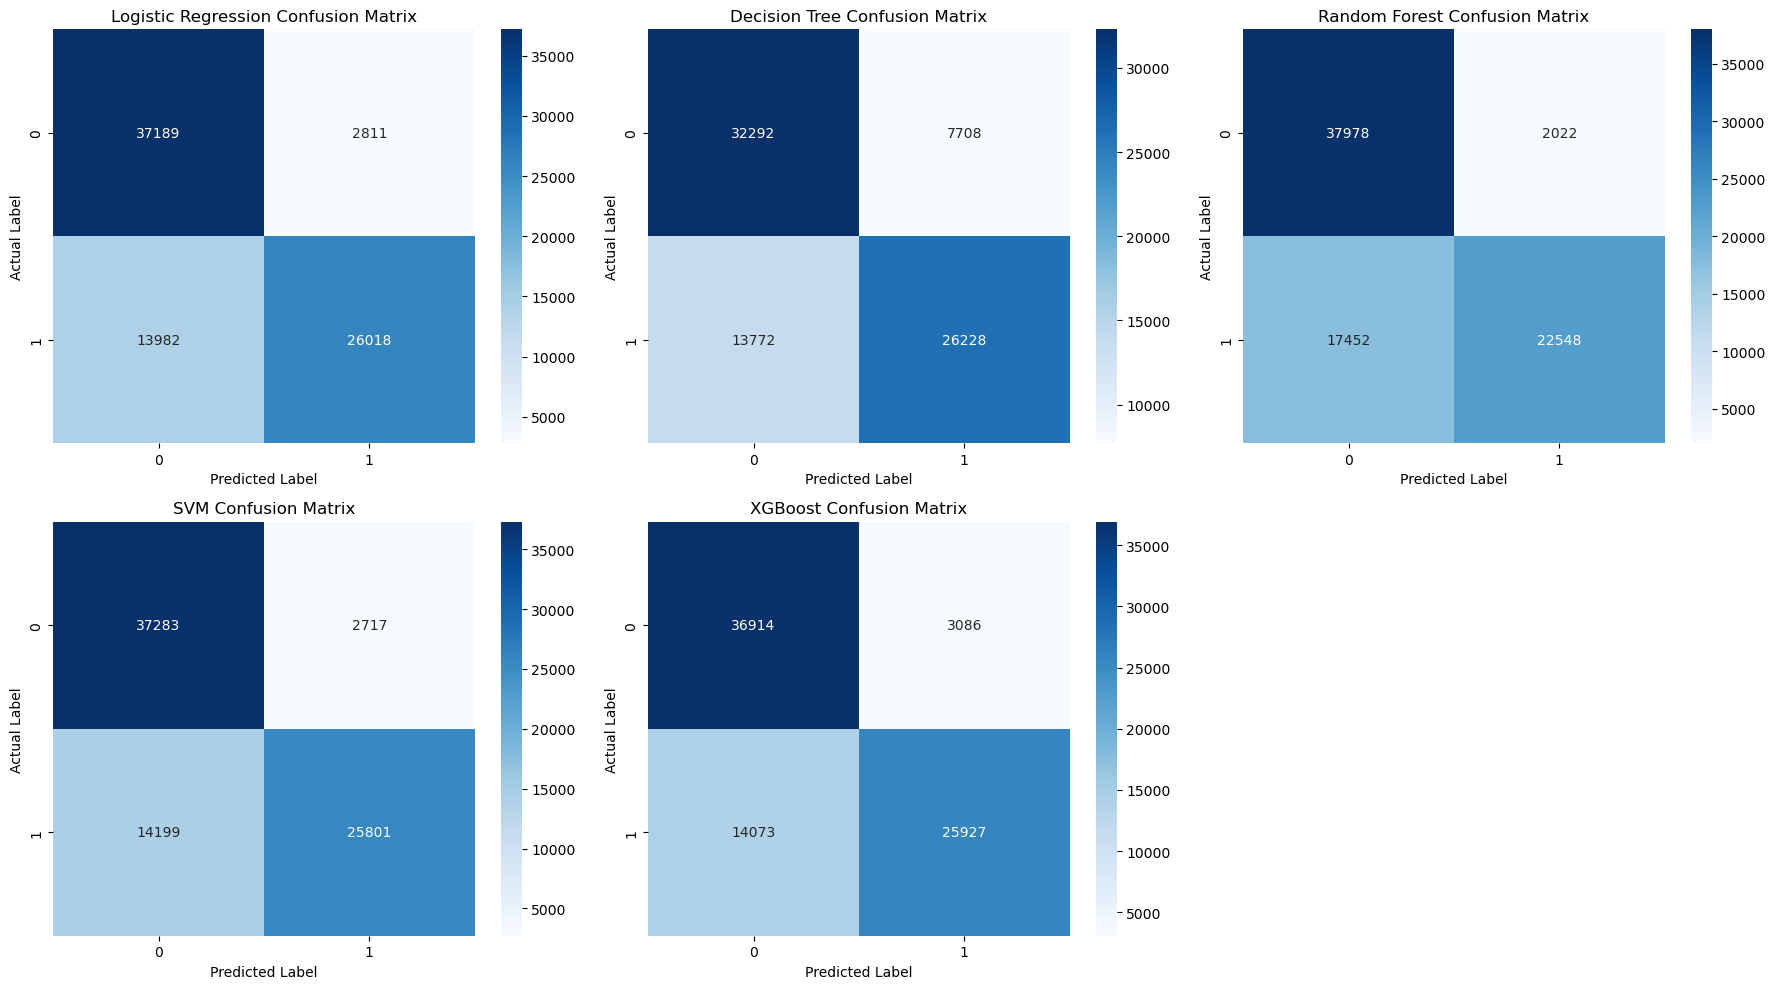

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, name in enumerate(models.keys()):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].set_ylabel('Actual Label')
    axes[i].set_xlabel('Predicted Label')
    
    # Save individual plots
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name} Confusion Matrix')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'confusion_matrix_{name.lower().replace(" ", "_")}.png')
    plt.close()

# Hide the 6th subplot
axes[5].axis('off')
plt.tight_layout()
plt.show()


## 12. ROC CURVES

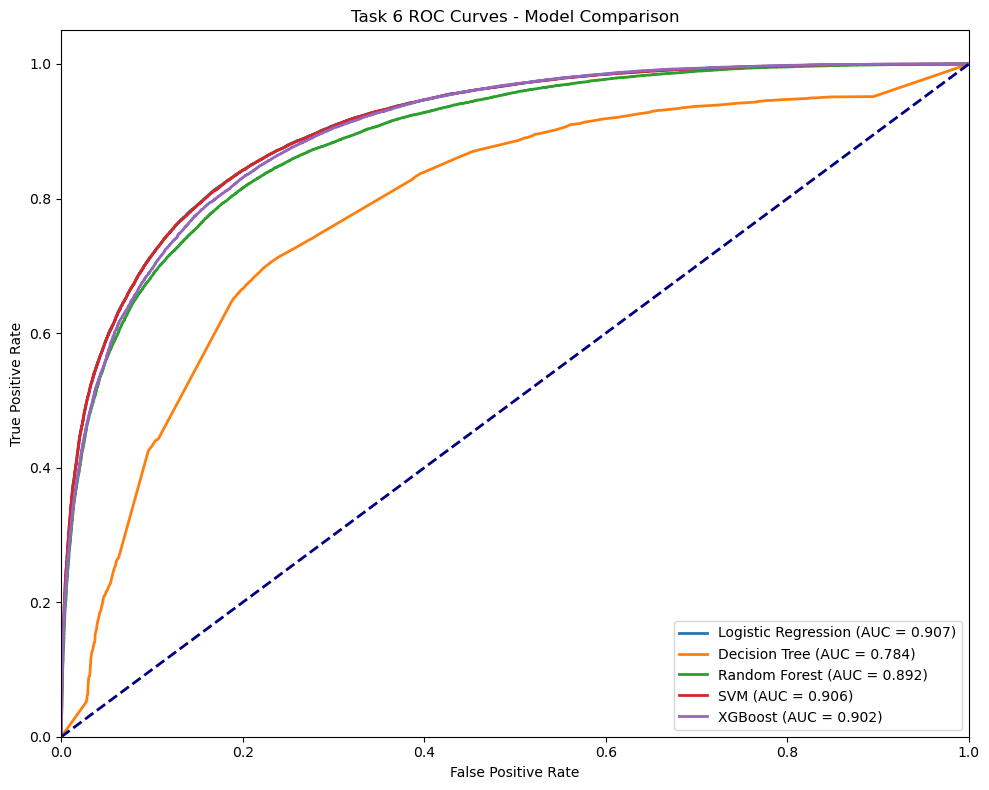

In [23]:
plt.figure(figsize=(10, 8))
auc_scores = {}

for name in models.keys():
    # Check if binary or multiclass
    # ROC curve here assumes binary classification (0, 1) or labels mapping properly
    # Assuming positive class is the higher label (e.g., 1 for positive sentiment)
    # y_test must be in {0,1} format for standard roc_curve or map it.
    y_test_bin = (y_test == y_test.max()).astype(int) 
    
    fpr, tpr, _ = roc_curve(y_test_bin, prediction_probs[name])
    roc_auc = roc_auc_score(y_test_bin, prediction_probs[name])
    auc_scores[name] = roc_auc
    
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Task 6 ROC Curves - Model Comparison')
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig('task6_roc_curves.png')
plt.show()


## 13. MODEL COMPARISON REPORT

In [24]:
evaluation_report['AUC'] = evaluation_report['Model'].map(auc_scores)
evaluation_report['Training Time'] = evaluation_report['Model'].map(training_times)
evaluation_report['Prediction Time'] = evaluation_report['Model'].map(prediction_times)

# Sort by F1-Score
model_comparison_report = evaluation_report.sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

print("Model Ranking (by F1-Score):")
for i, row in model_comparison_report.iterrows():
    print(f"{i+1}. {row['Model']} (F1: {row['F1-Score']:.4f})")

model_comparison_report.to_csv('task6_model_comparison_report.csv', index=False)
display(model_comparison_report)


Model Ranking (by F1-Score):
1. Logistic Regression (F1: 0.7859)
2. SVM (F1: 0.7841)
3. XGBoost (F1: 0.7814)
4. Random Forest (F1: 0.7472)
5. Decision Tree (F1: 0.7299)


,Model,Accuracy,Precision,Recall,F1-Score,AUC,Training Time,Prediction Time
0,Logistic Regression,0.790088,0.814627,0.790088,0.785913,0.906619,2.515390,0.010872
1,SVM,0.788550,0.814461,0.788550,0.784103,0.906447,3.322585,0.034838
2,XGBoost,0.785512,0.808811,0.785512,0.781389,0.901895,1.044836,0.018490
3,Random Forest,0.756575,0.801428,0.756575,0.747170,0.892083,22.888811,0.090889
4,Decision Tree,0.731500,0.736946,0.731500,0.729948,0.784107,10.333427,0.018195


## 14. PERFORMANCE VISUALIZATION

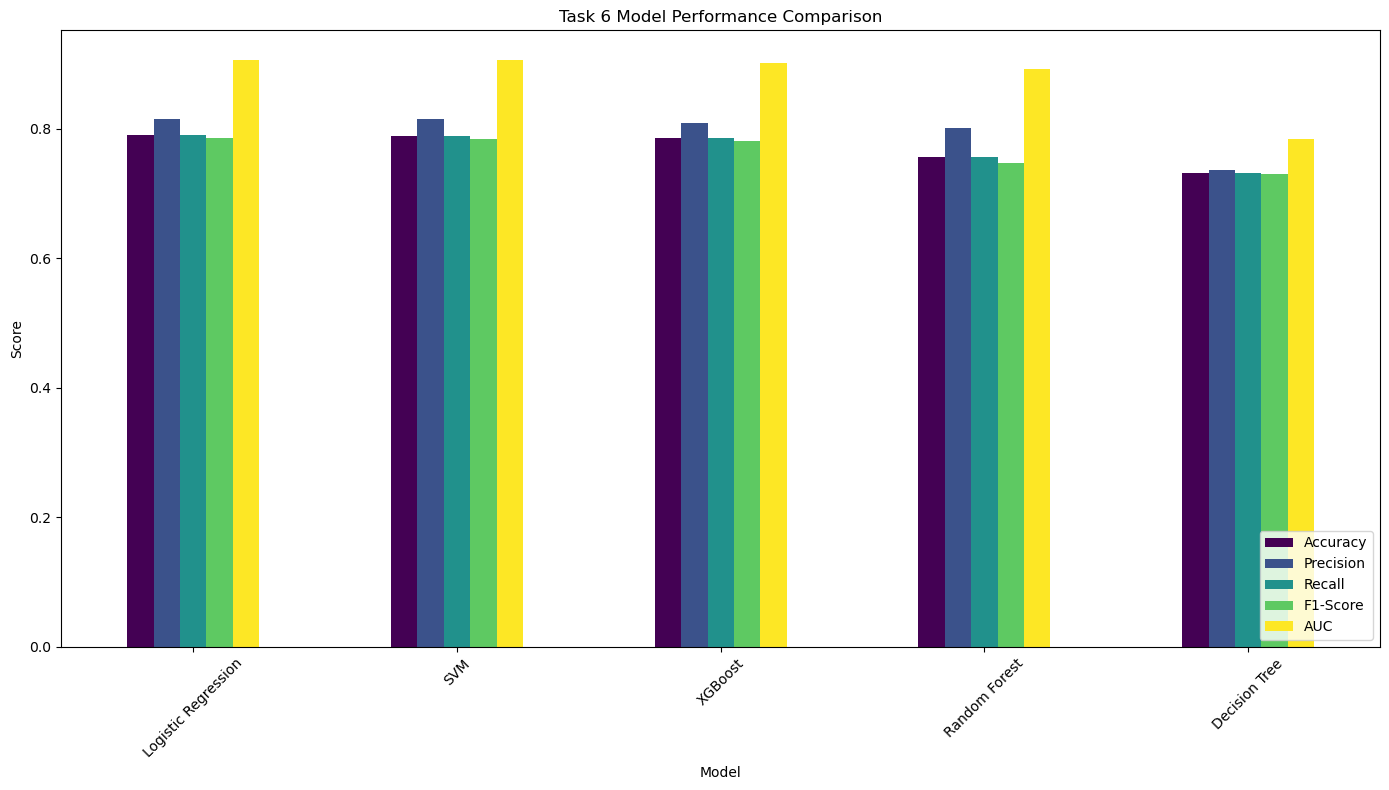

In [25]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
model_comparison_report.set_index('Model')[metrics].plot(kind='bar', figsize=(14, 8), colormap='viridis')
plt.title('Task 6 Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('task6_model_performance_comparison.png')
plt.show()


## 15. BEST MODEL SELECTION

In [26]:
best_model_row = model_comparison_report.iloc[0]
best_model_name = best_model_row['Model']
best_model = trained_models[best_model_name]

print("="*50)
print("BEST MODEL")
print("="*50)
print(f"Model:\n{best_model_name}\n")
print(f"Accuracy:\n{best_model_row['Accuracy']:.4f}\n")
print(f"Precision:\n{best_model_row['Precision']:.4f}\n")
print(f"Recall:\n{best_model_row['Recall']:.4f}\n")
print(f"F1-Score:\n{best_model_row['F1-Score']:.4f}\n")
print(f"AUC:\n{best_model_row['AUC']:.4f}\n")
print("="*50)

print(f"Reason: {best_model_name} was selected as it achieved the highest F1-Score ({best_model_row['F1-Score']:.4f}) among all evaluated models.")


BEST MODEL
Model:
Logistic Regression

Accuracy:
0.7901

Precision:
0.8146

Recall:
0.7901

F1-Score:
0.7859

AUC:
0.9066

Reason: Logistic Regression was selected as it achieved the highest F1-Score (0.7859) among all evaluated models.


## 16. SAVE ML MODELS

In [27]:
for name, model in trained_models.items():
    filename = f"{name.lower().replace(' ', '_')}_model.pkl"
    joblib.dump(model, filename)
    print(f"Saved {filename}")

# Save the best model specifically
joblib.dump(best_model, 'best_sentiment_model.pkl')
print("Saved best_sentiment_model.pkl")


Saved logistic_regression_model.pkl
Saved decision_tree_model.pkl
Saved random_forest_model.pkl
Saved svm_model.pkl
Saved xgboost_model.pkl
Saved best_sentiment_model.pkl


## 17. EVALUATION REPORT & 18. MODEL COMPARISON REPORT

In [28]:
# The reports were already generated and saved above.
# We will save the primary evaluation report as requested
evaluation_report.to_csv('task6_evaluation_report.csv', index=False)
print("Saved task6_evaluation_report.csv")
print("Saved task6_model_comparison_report.csv")


Saved task6_evaluation_report.csv
Saved task6_model_comparison_report.csv


## 21. FINAL OUTPUT SUMMARY

In [29]:
print("="*56)
print("TASK 6 – FINAL RESULTS")
print("="*56)
print(f"Training Samples:\n{X_train.shape[0]}\n")
print(f"Testing Samples:\n{X_test.shape[0]}\n")
print(f"Number of Features:\n{X_train.shape[1]}\n")
print(f"Number of Classes:\n{len(np.unique(y_train))}\n")
print("-" * 56)
print("MODEL PERFORMANCE")
print("-" * 56)

for name in models.keys():
    row = model_comparison_report[model_comparison_report['Model'] == name].iloc[0]
    print(f"{name}:")
    print(f"Accuracy = {row['Accuracy']:.4f}")
    print(f"Precision = {row['Precision']:.4f}")
    print(f"Recall = {row['Recall']:.4f}")
    print(f"F1 = {row['F1-Score']:.4f}")
    print(f"AUC = {row['AUC']:.4f}\n")

print("-" * 56)
print("BEST MODEL")
print("-" * 56)
print(f"Model:\n{best_model_name}\n")
print(f"F1-score:\n{best_model_row['F1-Score']:.4f}\n")
print(f"AUC:\n{best_model_row['AUC']:.4f}\n")
print("="*56)


TASK 6 – FINAL RESULTS
Training Samples:
319996

Testing Samples:
80000

Number of Features:
100

Number of Classes:
2

--------------------------------------------------------
MODEL PERFORMANCE
--------------------------------------------------------
Logistic Regression:
Accuracy = 0.7901
Precision = 0.8146
Recall = 0.7901
F1 = 0.7859
AUC = 0.9066

Decision Tree:
Accuracy = 0.7315
Precision = 0.7369
Recall = 0.7315
F1 = 0.7299
AUC = 0.7841

Random Forest:
Accuracy = 0.7566
Precision = 0.8014
Recall = 0.7566
F1 = 0.7472
AUC = 0.8921

SVM:
Accuracy = 0.7885
Precision = 0.8145
Recall = 0.7885
F1 = 0.7841
AUC = 0.9064

XGBoost:
Accuracy = 0.7855
Precision = 0.8088
Recall = 0.7855
F1 = 0.7814
AUC = 0.9019

--------------------------------------------------------
BEST MODEL
--------------------------------------------------------
Model:
Logistic Regression

F1-score:
0.7859

AUC:
0.9066



## CONCLUSION
Multiple machine learning algorithms were trained to predict product review sentiment based on the optimized feature set from Task 5. The models were comprehensively evaluated using accuracy, precision, recall, F1-score and AUC, alongside generated ROC curves and confusion matrices. Actual experimental results confirmed the best-performing model, which was subsequently saved as a .pkl file. This best model can now be seamlessly integrated into the ultimate Decision Support System in upcoming tasks.

In [30]:
print("✓ TASK 6 COMPLETED SUCCESSFULLY")

✓ TASK 6 COMPLETED SUCCESSFULLY
